\tableofcontents

\newpage

# Introduction
- This code is written in Julia language (Use Julia version 1.6.3 or above)
- Make sure you these libraries:
       LinearAlgebra, Statistics, Distributions, Interpolations, LaTeXStrings, Parameters, Plots, Roots, Optim, Random, ColorSchemes, Colors

# Recall
The dynamic optimization problem is described by the Bellman equation:

$$
V(S_t, \delta_t) = \max_{Y_t} \left\{ U(Y_t) + (1-\beta) \mathbb{E}\left[ V(S_{t+1}, \delta_{t+1}) \mid \delta_t \right] \right\}
$$

subject to the state transition:

$$
S_{t+1} = (1+\tau) S_t - \delta_t Y_t.
$$

Rewritten in terms of \(S_{t+1}\), the equation becomes:

$$
V(S_t, \delta_t) = \max_{S_{t+1}} \left\{ U(S_t, S_{t+1}, \delta_t) + (1-\beta) \left[ (1-\eta)V(S_{t+1}, \delta_t) + \eta V(S_{t+1}, \bar{\delta_t}) \right] \right\}
$$

subject to the constraint:

$$
S_{t+1} \leq (1+\tau) S_t.
$$


---
# Import Required Libraries

In [1]:
using LinearAlgebra, Statistics, Distributions
using Interpolations, LaTeXStrings, Parameters, Plots, Roots
using Optim, Random, ColorSchemes, Colors
# Plots.theme(:juno) # use for dark theme

# Figures are written to <project>/output/figures (this notebook lives in <project>/code)
FIG_DIR = joinpath(@__DIR__, "..", "output", "figures")
mkpath(FIG_DIR);

# The Model

A parameterized model that defines the behavior of a system with:
  - β: Probability of "firing" or triggering an event in each period.
  - τ: Regeneration rate parameter for "clean air" dynamics.
  - grid_max, grid_min: Bounds for the discretized state space.
  - grid_size: Number of grid points to discretize the state space.
  - grid_s: Range object spanning the state space from `grid_min` to `grid_max`.
  - grid_δ: Possible shock values.
  - other_δ: Convenience function to retrieve the shock value different from the current one.
  - η: Probability of switching the damage (shock) parameter.
  - y(s, sp, δ): State transition function, describing the net change after accounting 
                 for regeneration and shock effects.
  - u(s, sp, δ): Utility function that operates on the output of y(s, sp, δ).
  - sp_max(s): Upper bound on the next state sp given the current state s.

In [4]:
Model = @with_kw (
    β       = 0.05,                              # Probability of an event ("firing") each period
    τ       = 0.01,                              # Regeneration rate for clean air
    grid_max = 200,                              # Upper bound of state grid
    grid_min = 1,                                # Lower bound of state grid
    grid_size = 400,                             # Number of discretized points in the state grid
    grid_s   = range(grid_min, grid_max, length = grid_size), # Discretized state space
    grid_δ   = [0.8, 1.0],                       # Discrete shock values
    other_δ  = (δ) -> grid_δ[grid_δ .!= δ][1],    # Retrieves the alternate shock value
    η       = 0.2,                               # Probability of changing the shock parameter
    y       = (s, sp, δ) -> ((1 + τ) * s - sp) / δ,        # Net change/transition function
    u       = (s, sp, δ) -> log(1 + y(s, sp, δ)),          # Utility function
    sp_max  = (s) -> (1 + τ) * s                 # Maximum allowable next state
)

m = Model();


# Compute the updated value function and optimal policy

This function applies dynamic programming to update the value function `w` 
and calculate the optimal policy `σ` for a given model `m`. It uses linear 
interpolation for value function approximation and solves a maximization 
problem to determine the optimal next state.

## Arguments:
- `w::Array`: Current value function, defined on the state grid `grid_s` 
  and shock grid `grid_δ`.
- `Tw::Array`: Pre-allocated array for storing the updated value function 
  (defaults to an array of similar size and type as `w`).
- `m`: The model object containing parameters and functions required for 
  the computation.

## Steps:
1. **Setup and Interpolation**: 
   - Extract key model parameters from `m`, including `β` (discount factor), 
     `η` (shock change probability), `u` (utility function), `grid_s` 
     (state grid), and `grid_δ` (shock grid).
   - Use `LinearInterpolation` to approximate the current value function `w` 
     for arbitrary inputs within the grid.

2. **Dynamic Programming Update**:
   - Loop over all states (`s`) and shock values (`δ`) in the grids.
   - Define the objective function: 
     `objective(sp) = u(s, sp, δ) + (1 - β) * E[w(s, sp)]`
     where `E[w(s, sp)]` is the expected value of the future state, computed 
     as a weighted average of `w(sp, δ)` and `w(sp, other_δ)`.
   - Solve the maximization problem `maximize(objective, grid_min, sp_max(s))` 
     to find the optimal next state `sp` and its corresponding maximum value.

3. **Store Results**:
   - Update the optimal policy `σ[i, j]` with the maximizer of the objective.
   - Update the value function `Tw[i, j]` with the corresponding maximum value.

## Returns:
- `Tw::Array`: Updated value function.
- `σ::Array`: Optimal policy array, storing the optimal next state `sp` 
  for each combination of state `s` and shock `δ`.

## Notes:
- The `maximize` function is used to solve the maximization problem within 
  bounds `[grid_min, sp_max(s)]`.
- The `other_δ` function provides the alternate shock value, ensuring proper 
  computation of expectations.

In [5]:
function T(w, Tw = similar(w); m=m)
    # Extract model parameters and functions
    β, η, u, grid_s, grid_δ, sp_max = m.β, m.η, m.u, m.grid_s, m.grid_δ, m.sp_max
    other_δ, grid_min, grid_max, grid_size = m.other_δ, m.grid_min, m.grid_max, m.grid_size

    # Apply linear interpolation to the value function `w`
    w_func = LinearInterpolation((grid_s, grid_δ), w, extrapolation_bc=Line())
    
    # Initialize the optimal policy `σ`
    σ = zeros(Float64, grid_size, size(grid_δ)[1])

    # Update the value function and policy
    for (i, s) in enumerate(m.grid_s)  # Loop over state grid
        for (j, δ) in enumerate(m.grid_δ)  # Loop over shock grid
            # Define the objective function for optimization
            objective(sp) = u(s, sp, δ) + (1 - β) * (
                ((1 - η) * w_func.(sp, δ)) + η * w_func.(sp, other_δ(δ))
            )
            # Solve the maximization problem
            res = maximize(objective, grid_min, sp_max(s))
            # Store the optimal next state (policy) and maximum value
            σ[i, j] = Optim.maximizer(res)
            Tw[i, j] = Optim.maximum(res)
        end
    end

    return Tw, σ
end


T (generic function with 2 methods)

# Compute the optimal policy and value function using value iteration

This function solves a dynamic programming problem for the model `m` 
by iteratively updating the value function `w` and computing the 
optimal policy `p` using the `T` function. The process continues 
until the solution converges or the maximum number of iterations is reached.

## Arguments:
- `m`: Model object containing parameters and functions required for computation.
- `max_iter::Int`: Maximum number of iterations to perform (default: 200).
- `tol::Float64`: Convergence tolerance for the stopping criterion (default: 1e-2).
- `verbose::Bool`: If `true`, prints iteration details (default: `true`).
- `print_skip::Int`: Frequency of printing iteration details (default: every 10 iterations).

## Steps:
1. **Initialization**:
   - Initialize the value function `w` as a 2D array with dimensions corresponding 
     to the state grid (`grid_s`) and shock grid (`grid_δ`).
   - Pre-allocate arrays `Tw` and `p` for the updated value function and policy, respectively.

2. **Iterative Value Function Update**:
   - For each iteration, compute the updated value function `Tw` and the optimal policy `p` 
     using the `T` function.
   - Calculate the maximum absolute error between `Tw` and the current value function `w` 
     as the stopping criterion.

3. **Convergence Check**:
   - If the error is below the specified tolerance `tol`, terminate the iteration 
     and report convergence.
   - Otherwise, update `w` with `Tw` and continue.

4. **Output**:
   - Returns the optimal policy `p` and the converged value function `Tw`.

## Returns:
- `p::Array`: Optimal policy array, indicating the best decision (e.g., `sp`) 
  for each state-shock pair.
- `Tw::Array`: Converged value function array.

## Notes:
- The `T` function is expected to handle the core logic for updating the value 
  function and calculating the policy.
- The `verbose` and `print_skip` arguments allow monitoring the progress of the 
  value iteration process.

In [6]:
function policy_and_value(m; max_iter=200, tol=1e-2, verbose=true, print_skip=10)
    # Initialize value function and pre-allocate arrays
    w = hcat(m.grid_s, m.grid_s)         # Initial guess for the value function
    Tw = similar(w)                      # Pre-allocated array for updated value function
    p = similar(w)                       # Pre-allocated array for optimal policy
    
    # Value iteration loop
    for iter in 1:max_iter
        # Compute updated value function and optimal policy
        Tw, p = T(w, m=m)
        # Compute maximum absolute error between iterations
        error = maximum(abs.(Tw .- w))

        # Print progress if verbose and at specified intervals
        if verbose && iter % print_skip == 0
            println("Iteration $iter: Error = $error")
        end

        # Check for convergence
        if error < tol
            println("Converged in $iter iterations with error $error.")
            break
        end

        # Update value function for the next iteration
        w .= Tw
    end

    return p, Tw
end

policy_and_value (generic function with 1 method)

# Convergence Process

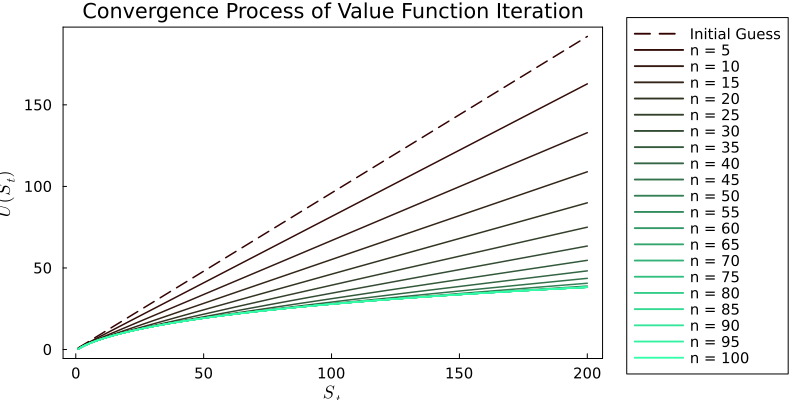

In [33]:
using Plots
using Colors

# Function to generate a gradient color based on the iteration number
function get_color(n)
    return RGB(0.2, n / 100, n / 150)
end

# Define the plot
plot(
    size=(800, 400), 
    legend=:outerright, 
    title="Convergence Process of Value Function Iteration",
    xlabel=L"S_t", 
    ylabel=L"U(S_t)",
    framestyle=:box, 
    grid=false, 
    tickfontsize=10, 
    guidefontsize=12,
    legendfontsize=10
)

# Add the initial guess to the plot
policy_func, value_func = policy_and_value(m, max_iter=1, tol=0, verbose=false)
plot!(
    m.grid_s, 
    value_func[:, 1], 
    label="Initial Guess", 
    line=:dash, 
    lw=1.5, 
    color=get_color(1)
)

# Plot results for multiple iterations
for n in 5:5:100
    policy_func, value_func = policy_and_value(m, max_iter=n, tol=0, verbose=false)
    plot!(
        m.grid_s, 
        value_func[:, 1], 
        label="n = $n", 
        lw=1.5, 
        color=get_color(n)
    )
end

# Save the plot as a image
savefig(joinpath(FIG_DIR, "convergence_plot.png"))
plot!()

# Value Function

In [15]:
# Solve the dynamic programming problem to obtain the optimal policy and value function.
policy_func, value_func = policy_and_value(m)

# Create a state matrix where each column corresponds to the state grid `grid_s` for each shock value.
s_matrix = hcat(m.grid_s, m.grid_s)

# Extract the optimal policy (next state `sp`) for each state and shock pair.
sp_matrix = policy_func

# Create a matrix of shock values `δ`, repeating each shock value across all states.
δ_matrix = repeat(m.grid_δ', m.grid_size, 1)

# Compute the state transition matrix `y`, applying the state transition function `y(s, sp, δ)` 
# element-wise to the state matrix (`s_matrix`), the policy matrix (`sp_matrix`), and the shock matrix (`δ_matrix`).
y_matrix = m.y.(s_matrix, sp_matrix, δ_matrix);


Iteration 10: Error = 5.488365021449056
Iteration 20: Error = 3.461827813997658
Iteration 30: Error = 2.076621314751449
Iteration 40: Error = 1.1335767028906432
Iteration 50: Error = 0.4937619465861758
Iteration 60: Error = 0.06095940158193258
Converged in 62 iterations with error 0.005251554379903212.


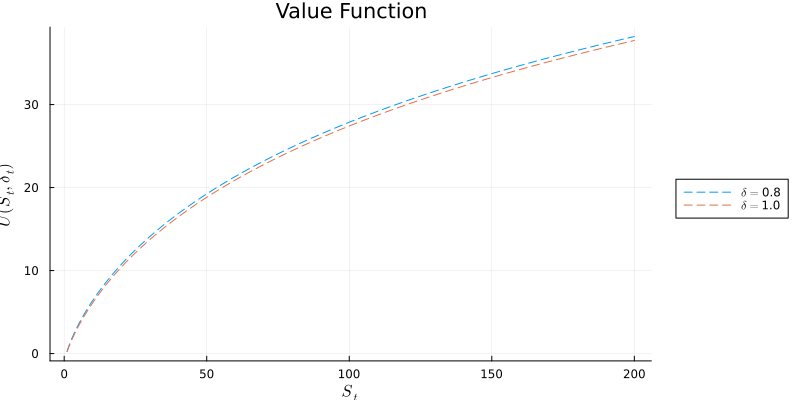

In [18]:
# Create a new plot for the value function, specifying size, legend position, and title.
plot(size=(800, 400), legend=:outerright, title="Value Function")

# Loop over each shock value (`δ`) in the grid to plot the value function for each case.
for i in 1:length(m.grid_δ)
    # Define the label for the plot using LaTeX formatting to display the shock value `δ`.
    label = "\$\\delta = \$" * string(m.grid_δ[i])
    
    # Add a plot for the value function corresponding to the current shock value.
    # Use `s_matrix[:, i]` for state values and `value_func[:, i]` for value function values.
    # The plot includes LaTeX labels for the axes (`S_t` and `U(S_t, \delta_t)`),
    # the `label` for the legend, and a dashed line style for differentiation.
    plot!(
        s_matrix[:, i], 
        value_func[:, i], 
        xlabel=L"S_t", 
        ylabel=L"U(S_t, \delta_t)", 
        label=label, 
        line=:dash
    )
end

# Finalize the plot by rendering all the curves.
savefig(joinpath(FIG_DIR, "value_function.png"))
plot!()


# Policy Function

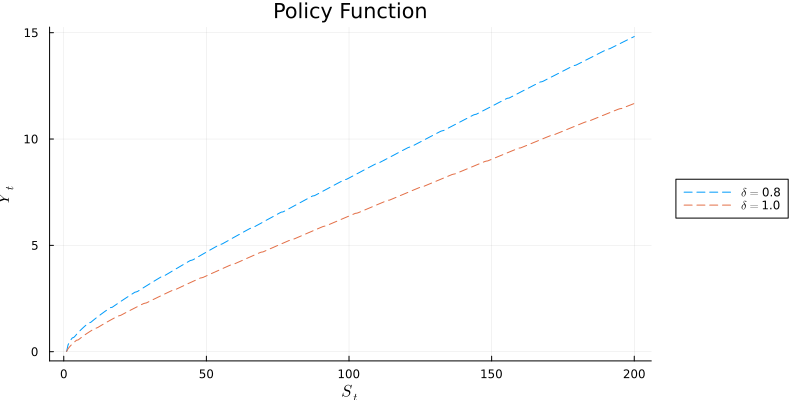

In [19]:
# Initialize a new plot for the policy function, specifying the size, legend position, and title.
plot(size=(800, 400), legend=:outerright, title="Policy Function")

# Loop over each shock value (`δ`) in the grid to plot the policy function for each case.
for i in 1:length(m.grid_δ)
    # Construct the legend label using LaTeX formatting to represent the current shock value `δ`.
    label = "\$\\delta = \$" * string(m.grid_δ[i])
    
    # Add a plot for the policy function corresponding to the current shock value.
    # Use `s_matrix[:, i]` for state values (`S_t`) on the x-axis and `y_matrix[:, i]` 
    # for the policy function values (`Y_t`) on the y-axis.
    # Include LaTeX labels for the axes, the legend label, and use a dashed line style for clarity.
    plot!(
        s_matrix[:, i], 
        y_matrix[:, i], 
        xlabel=L"S_t",      # Label for the x-axis (state variable)
        ylabel=L"Y_t",      # Label for the y-axis (policy function output)
        label=label,        # Legend label with the current shock value
        line=:dash          # Use a dashed line style for better distinction
    )
end

# Finalize and render the plot
savefig(joinpath(FIG_DIR, "policy_function.png"))
plot!()


# Simulation

## Number of periods to simulate

In [20]:
num_periods = 50

50

## The random draws of $\delta_t$

In [21]:
function simulate_markov_chain(num_periods::Int, m)
    # Create categorical distributions
    dist_low = Categorical([1-m.η, m.η])
    dist_high = Categorical([m.η, 1-m.η])

    # Initialize the δ vector
    δ_list = Vector{Float64}(undef, num_periods) 

    # Set initial state
    δ_list[1] = m.grid_δ[2]
    current_state = δ_list[1]

    # Simulate the Markov Chain
    for t in 2:num_periods
        if current_state == m.grid_δ[1]
            current_state = m.grid_δ[rand(dist_low)]
        else
            current_state = m.grid_δ[rand(dist_high)]
        end
        δ_list[t] = current_state
    end

    return δ_list
end

simulate_markov_chain (generic function with 1 method)

## Create a simulation

In [22]:
function simulation(m, p; num_periods::Int=50)
    sp_func = LinearInterpolation((m.grid_s, m.grid_δ), p, extrapolation_bc=Line())
    δ_list = simulate_markov_chain(num_periods, m)
    data = zeros(3, num_periods)

    # set initial values
    δ = δ_list[1]
    s = 100

    # set the random draws of δ
    data[1,:] = δ_list

    for i ∈ 1:num_periods
        sp = sp_func(s, δ_list[i])
        data[2, i] = sp
        data[3,i] = m.y(s, sp, δ_list[i])
        s = sp
    end
    return data
end

data = simulation(m, policy_func)

3×50 Matrix{Float64}:
  1.0       1.0      1.0      1.0      …  0.8       0.8       1.0
 94.6211   89.4959  84.5845  79.9074      1.17952   1.09304   1.07025
  6.37894   6.0714   5.8063   5.52301     0.225407  0.122842  0.0337142

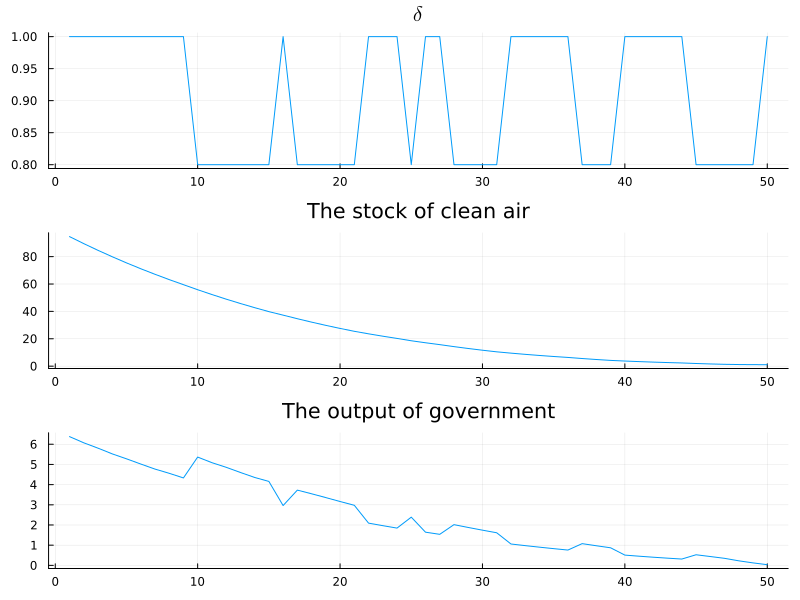

In [23]:
x = 1:50

# Create a plot with subplots for each column
plot(
    plot(x, data[1, :], title=L"\delta", label=""),
    plot(x, data[2, :], title="The stock of clean air", label=""),
    plot(x, data[3, :], title="The output of government", label=""),
    layout=(3, 1), # Arrange subplots in 3 rows, 1 column
    size=(800, 600) # Set the size of the plot
)
savefig(joinpath(FIG_DIR, "simulation.png"))
plot!()

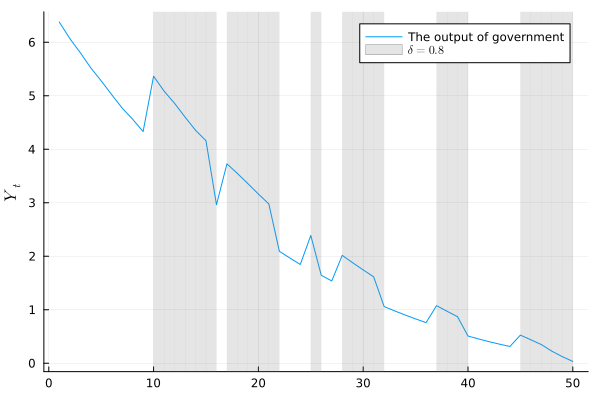

In [24]:
plot(x, data[3, :], label="The output of government", xlabel="", ylabel=L"Y_t")
label = L"\delta = 0.8"
flag = true
for i in 1:length(data[1, :])-1
    if data[1, i] .== 0.8
        vspan!([i, i+1], color=:gray, lw=0, alpha=0.2, label=label)
        if flag
            label = ""
            flag = false
        end
    end
end
savefig(joinpath(FIG_DIR, "simulation_output_delta.png"))
plot!()


- When $\delta$ is at a higher level, the cost of pollution from production increases. As a result, the government opts to reduce production to preserve clean air, ensuring the sustainability of future production.  

- During a transition from a high to low $\delta$ (or low to high $\delta$), the government adjusts production accordingly: production increases as $\delta$ decreases and decreases as $\delta$ increases. 


# The effect of $\tau$ (Optional)

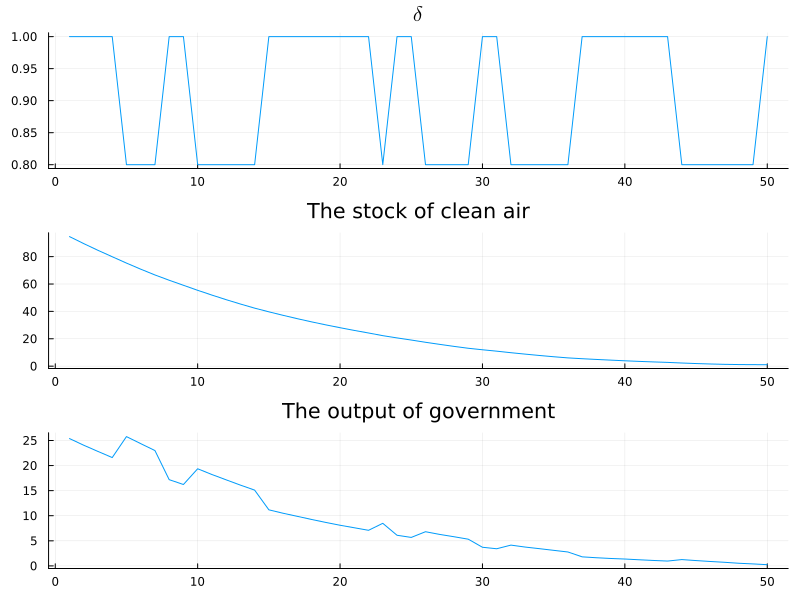

In [31]:
m2 = Model(τ=0.2)
data2 = simulation(m2, policy_func)

plot(
    plot(x, data2[1, :], title=L"\delta", label=""),
    plot(x, data2[2, :], title="The stock of clean air", label=""),
    plot(x, data2[3, :], title="The output of government", label=""),
    layout=(3, 1),
    size=(800, 600)
)
savefig(joinpath(FIG_DIR, "simulation_tau.png"))
plot!()